In [ ]:
pip install pyspark

In [ ]:
import os
os.makedirs("data/raw", exist_ok=True)       # raw CSV yahan rakhni hai
os.makedirs("data/parquet", exist_ok=True)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, shutil, glob
os.makedirs("data/raw", exist_ok=True)

In [ ]:
for f in glob.glob("/content/drive/MyDrive/scada_raw/*F95*.csv"):
    shutil.copy(f, "data/raw/")

print(os.listdir("data/raw"))

[]


In [ ]:
import os

# 1) Drive mount hua ya nahi
print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))

# 2) My Drive mein kaunse folders/files hain
print(os.listdir("/content/drive/MyDrive"))

Drive mounted: True
['RES ashwit (1).pdf', 'RES ashwit.pdf', 'a4bdc263-fa19-4c4d-9706-d1eb7193bde9_7.pdf', 'OFF campus ashwit (2).pdf', 'OFF campus ashwit (1).pdf', 'OFFU ashwit.pdf', 'OFF campus ashwit.pdf', 'Video Project 1.mp4', 'Colab Notebooks', 'cos-project-checkpoints', 'Turbine_data_R80711_2013-2018_F95.csv', 'Turbine_data_R80711_2013-2018_F99.csv', 'Turbine_data_R80721_2013-2018_F95.csv', 'Turbine_data_R80721_2013-2018_F99.csv', 'Turbine_data_R80736_2013-2018_F95.csv', 'Turbine_data_R80736_2013-2018_F99.csv', 'Turbine_data_R80790_2013-2018_F95.csv', 'Turbine_data_R80790_2013-2018_F99.csv', 'scada_project']


In [ ]:
import glob, shutil, os

files = glob.glob("/content/drive/MyDrive/**/*F*.csv", recursive=True)
print("Mili files:", len(files))
for f in files:
    print(f)

os.makedirs("data/raw", exist_ok=True)
for f in files:
    shutil.copy(f, "data/raw/")       # local disk pe copy (Spark ke liye fast)

print(os.listdir("data/raw"))

Mili files: 8
/content/drive/MyDrive/Turbine_data_R80711_2013-2018_F95.csv
/content/drive/MyDrive/Turbine_data_R80711_2013-2018_F99.csv
/content/drive/MyDrive/Turbine_data_R80721_2013-2018_F95.csv
/content/drive/MyDrive/Turbine_data_R80721_2013-2018_F99.csv
/content/drive/MyDrive/Turbine_data_R80736_2013-2018_F95.csv
/content/drive/MyDrive/Turbine_data_R80736_2013-2018_F99.csv
/content/drive/MyDrive/Turbine_data_R80790_2013-2018_F95.csv
/content/drive/MyDrive/Turbine_data_R80790_2013-2018_F99.csv
['Turbine_data_R80711_2013-2018_F95.csv', 'Turbine_data_R80711_2013-2018_F99.csv', 'Turbine_data_R80790_2013-2018_F99.csv', 'Turbine_data_R80790_2013-2018_F95.csv', 'Turbine_data_R80721_2013-2018_F95.csv', 'Turbine_data_R80736_2013-2018_F99.csv', 'Turbine_data_R80736_2013-2018_F95.csv', 'Turbine_data_R80721_2013-2018_F99.csv']


In [ ]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .appName("scada-ingest")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())

raw = (spark.read
       .option("header", True)
       .option("sep", ",")             # head ke output ke hisaab se "," ya ";"
       .option("inferSchema", True)
       .csv("data/raw/*.csv")
       .withColumn("source_file", F.regexp_extract(F.input_file_name(), r"(F\d+)\.csv", 1)))  # F95 ya F99

raw.printSchema()
print("raw rows:", raw.count())

# Overlap check: kya ek hi turbine + timestamp dono files mein hai?
dups = (raw.groupBy("Wind_turbine_name", "Date_time").count()
           .filter("count > 1").count())
print("Repeated (turbine, timestamp) pairs:", dups)

raw.groupBy("source_file").count().show()   # F95 vs F99 ke rows

root
 |-- Date_time: timestamp (nullable = true)
 |-- Wind_turbine_name: string (nullable = true)
 |-- Q_avg: double (nullable = true)
 |-- S_avg: double (nullable = true)
 |-- P_avg: double (nullable = true)
 |-- Git_avg: double (nullable = true)
 |-- Ws_avg: double (nullable = true)
 |-- Ds_avg: double (nullable = true)
 |-- DCs_avg: double (nullable = true)
 |-- Gost_avg: double (nullable = true)
 |-- Gb2t_avg: double (nullable = true)
 |-- Db2t_avg: double (nullable = true)
 |-- Gb1t_avg: double (nullable = true)
 |-- Db1t_avg: double (nullable = true)
 |-- Dst_avg: double (nullable = true)
 |-- Yt_avg: double (nullable = true)
 |-- Rbt_avg: double (nullable = true)
 |-- Rt_avg: double (nullable = true)
 |-- source_file: string (nullable = false)

raw rows: 1594831
Repeated (turbine, timestamp) pairs: 793379
+-----------+------+
|source_file| count|
+-----------+------+
|        F99|801331|
|        F95|793500|
+-----------+------+



In [ ]:
# Naam simple karo: lowercase, aur turbine_id / ts
df = raw
for c in df.columns:
    df = df.withColumnRenamed(c, c.lower())
df = (df.withColumnRenamed("wind_turbine_name", "turbine_id")
        .withColumnRenamed("date_time", "ts"))          # ts pehle se timestamp hai, cast ki zaroorat nahi

print("rows start:", df.count())

# 1) Overlap check: kya F95 aur F99 mein same (turbine, ts) hai?
n_dups = df.groupBy("turbine_id", "ts").count().filter("count > 1").count()
print("Repeated (turbine, ts) pairs:", n_dups)           # 0 hona achha hai
df.groupBy("source_file").count().show()                 # F95 vs F99 rows

# 2) Timestamp ya turbine ke bina row bekaar hai
df = df.dropna(subset=["ts", "turbine_id"])
df = df.dropDuplicates(["turbine_id", "ts"])             # n_dups = 0 ho to kuch nahi hatega

# 3) Null % report (abhi impute nahi kar rahe, pehle dekhte hain kitna missing hai)
sensor_cols = [c for c in df.columns if c not in ("turbine_id", "ts", "source_file")]
df.select([(F.sum(F.col(c).isNull().cast("int")) / F.count("*") * 100).alias(c)
           for c in sensor_cols]).show(truncate=False)

# 4) Power ya wind speed ke bina row model ke kaam ki nahi
df = df.dropna(subset=["p_avg", "ws_avg"])
print("rows after cleaning:", df.count())

# 5) Partition column: turbine_id + year_month (date nahi, warna chhoti files bahut banengi)
df = df.withColumn("year_month", F.date_format("ts", "yyyy-MM"))

(df.write.mode("overwrite")
   .partitionBy("turbine_id", "year_month")
   .parquet("data/parquet/scada"))

print("rows in parquet:", spark.read.parquet("data/parquet/scada").count())

rows start: 1594831
Repeated (turbine, ts) pairs: 793379
+-----------+------+
|source_file| count|
+-----------+------+
|        F99|801331|
|        F95|793500|
+-----------+------+

+-----+-----+-----+-------+------+------+-------+--------+--------+--------+--------+--------+-------+------+-------+------+
|q_avg|s_avg|p_avg|git_avg|ws_avg|ds_avg|dcs_avg|gost_avg|gb2t_avg|db2t_avg|gb1t_avg|db1t_avg|dst_avg|yt_avg|rbt_avg|rt_avg|
+-----+-----+-----+-------+------+------+-------+--------+--------+--------+--------+--------+-------+------+-------+------+
|0.0  |0.0  |0.0  |0.0    |0.0   |0.0   |0.0    |0.0     |0.0     |0.0     |0.0     |0.0     |0.0    |0.0   |0.0    |0.0   |
+-----+-----+-----+-------+------+------+-------+--------+--------+--------+--------+--------+-------+------+-------+------+

rows after cleaning: 801209
rows in parquet: 801209


In [ ]:
import os
os.makedirs("/content/drive/MyDrive/scada_project", exist_ok=True)

# Column naam simple karo (agar `base` pehle se bana hai to ye bhi chalega)
base = raw
for c in base.columns:
    base = base.withColumnRenamed(c, c.lower())
base = (base.withColumnRenamed("wind_turbine_name", "turbine_id")
            .withColumnRenamed("date_time", "ts"))

# Drive mein Parquet likho. 4 turbines x 2 source = 8 folders, small-file problem nahi hogi
(base.write.mode("overwrite")
     .partitionBy("turbine_id", "source_file")
     .parquet("/content/drive/MyDrive/scada_project/checkpoint_raw"))

print("saved rows:", spark.read.parquet("/content/drive/MyDrive/scada_project/checkpoint_raw").count())

saved rows: 1594831


In [ ]:
# 1) Drive mount
from google.colab import drive
drive.mount('/content/drive')

# 2) PySpark (agar import error aaye to pehle !pip install pyspark chalao)
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder
         .appName("scada")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())

# 3) Checkpoint se seedha data load, CSV dobara padhne ki zaroorat nahi
base = spark.read.parquet("/content/drive/MyDrive/scada_project/checkpoint_raw")
print("rows:", base.count())            # 1,594,831
base.printSchema()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
rows: 1594831
root
 |-- ts: timestamp (nullable = true)
 |-- q_avg: double (nullable = true)
 |-- s_avg: double (nullable = true)
 |-- p_avg: double (nullable = true)
 |-- git_avg: double (nullable = true)
 |-- ws_avg: double (nullable = true)
 |-- ds_avg: double (nullable = true)
 |-- dcs_avg: double (nullable = true)
 |-- gost_avg: double (nullable = true)
 |-- gb2t_avg: double (nullable = true)
 |-- db2t_avg: double (nullable = true)
 |-- gb1t_avg: double (nullable = true)
 |-- db1t_avg: double (nullable = true)
 |-- dst_avg: double (nullable = true)
 |-- yt_avg: double (nullable = true)
 |-- rbt_avg: double (nullable = true)
 |-- rt_avg: double (nullable = true)
 |-- turbine_id: string (nullable = true)
 |-- source_file: string (nullable = true)



In [ ]:
from pyspark.sql import functions as F

# ---------- Check 1: F95 vs F99 ki values (overlapping timestamps pe) ----------
a = base.filter("source_file = 'F95'").alias("a")
b = base.filter("source_file = 'F99'").alias("b")
j = a.join(b, ["turbine_id", "ts"])                  # sirf wo timestamps jo dono mein hain

check = ["p_avg", "ws_avg", "gb1t_avg", "db1t_avg"]  # power, wind speed, 2 bearing temps
print("=== CHECK 1: F95 vs F99 ===")
j.select(
    F.count("*").alias("overlap_rows"),
    *[F.sum((~F.col(f"a.{c}").eqNullSafe(F.col(f"b.{c}"))).cast("int")).alias(f"{c}_differs") for c in check],
    *[F.round(F.avg(F.abs(F.col(f"a.{c}") - F.col(f"b.{c}"))), 4).alias(f"{c}_mean_absdiff") for c in check]
).show(truncate=False)

j.select("turbine_id", "ts",
         F.col("a.p_avg").alias("p_F95"), F.col("b.p_avg").alias("p_F99"),
         F.col("a.gb1t_avg").alias("gb1t_F95"), F.col("b.gb1t_avg").alias("gb1t_F99")
).show(5, truncate=False)

# ---------- Check 2: time series mein gaps ----------
print("=== CHECK 2: gaps per turbine ===")
(base.dropDuplicates(["turbine_id", "ts"])           # sirf gaps ginne ke liye, data nahi badal raha
     .groupBy("turbine_id")
     .agg(F.count("*").alias("rows"), F.min("ts").alias("first"), F.max("ts").alias("last"))
     .withColumn("expected_10min_rows",
                 ((F.unix_timestamp("last") - F.unix_timestamp("first")) / 600 + 1).cast("long"))
     .withColumn("missing_pct", F.round((1 - F.col("rows") / F.col("expected_10min_rows")) * 100, 1))
     .show(truncate=False))

=== CHECK 1: F95 vs F99 ===
+------------+-------------+--------------+----------------+----------------+------------------+-------------------+---------------------+---------------------+
|overlap_rows|p_avg_differs|ws_avg_differs|gb1t_avg_differs|db1t_avg_differs|p_avg_mean_absdiff|ws_avg_mean_absdiff|gb1t_avg_mean_absdiff|db1t_avg_mean_absdiff|
+------------+-------------+--------------+----------------+----------------+------------------+-------------------+---------------------+---------------------+
|793743      |243          |243           |243             |241             |0.0627            |3.0E-4             |0.001                |0.0013               |
+------------+-------------+--------------+----------------+----------------+------------------+-------------------+---------------------+---------------------+

+----------+-------------------+---------+---------+---------+---------+
|turbine_id|ts                 |p_F95    |p_F99    |gb1t_F95 |gb1t_F99 |
+----------+--------

In [ ]:
from pyspark.sql import Window, functions as F

# 1) Check: ek hi source file ke andar (turbine, ts) repeat to nahi? (join count 793,743 vs 793,379 ka farak)
within = base.groupBy("turbine_id", "ts", "source_file").count().filter("count > 1").count()
print("Duplicate (turbine, ts) within same file:", within)

# 2) Priority rule: F99 pehle, nahi to F95
df = base.withColumn("prio", F.when(F.col("source_file") == "F99", 1).otherwise(2))
w = Window.partitionBy("turbine_id", "ts").orderBy("prio", "source_file")   # tie ho to bhi deterministic
df = (df.withColumn("rn", F.row_number().over(w))
        .filter("rn = 1")
        .drop("prio", "rn"))

# 3) Power ya wind speed null ho to row bekaar (abhi nulls 0 hain, safety ke liye)
df = df.dropna(subset=["p_avg", "ws_avg"])

print("final unique rows:", df.count())
df.groupBy("source_file").count().show()      # kitni rows F99 se aayi, kitni F95 se

# 4) Drive mein likho: turbine_id se partition, repartition se har turbine ki 1 file
(df.repartition("turbine_id")
   .write.mode("overwrite")
   .partitionBy("turbine_id")
   .parquet("/content/drive/MyDrive/scada_project/parquet/scada"))

check = spark.read.parquet("/content/drive/MyDrive/scada_project/parquet/scada")
print("rows in parquet:", check.count())
check.filter("turbine_id = 'R80711'").explain()   # PartitionFilters line dikhni chahiye

Duplicate (turbine, ts) within same file: 243
final unique rows: 801209
+-----------+------+
|source_file| count|
+-----------+------+
|        F99|801209|
+-----------+------+

rows in parquet: 801209
== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [ts#1429,q_avg#1430,s_avg#1431,p_avg#1432,git_avg#1433,ws_avg#1434,ds_avg#1435,dcs_avg#1436,gost_avg#1437,gb2t_avg#1438,db2t_avg#1439,gb1t_avg#1440,db1t_avg#1441,dst_avg#1442,yt_avg#1443,rbt_avg#1444,rt_avg#1445,source_file#1446,turbine_id#1447] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/content/drive/MyDrive/scada_project/parquet/scada], PartitionFilters: [isnotnull(turbine_id#1447), (turbine_id#1447 = R80711)], PushedFilters: [], ReadSchema: struct<ts:timestamp,q_avg:double,s_avg:double,p_avg:double,git_avg:double,ws_avg:double,ds_avg:do...




In [ ]:
df = spark.read.parquet("/content/drive/MyDrive/scada_project/parquet/scada")
df.createOrReplaceTempView("scada")

# 1) Hourly aggregates: har turbine ke har ghante ka mean/std (6 readings of 10-min)
spark.sql("""
    SELECT turbine_id,
           date_trunc('hour', ts)  AS hour_ts,
           COUNT(*)                AS h_n,          -- us ghante mein kitni readings thi (gap detect karne ke liye)
           AVG(p_avg)    AS h_p_mean,    STDDEV(p_avg)    AS h_p_std,
           AVG(ws_avg)   AS h_ws_mean,   STDDEV(ws_avg)   AS h_ws_std,
           AVG(gb1t_avg) AS h_gb1t_mean, STDDEV(gb1t_avg) AS h_gb1t_std,
           AVG(db1t_avg) AS h_db1t_mean, STDDEV(db1t_avg) AS h_db1t_std
    FROM scada
    GROUP BY turbine_id, date_trunc('hour', ts)
""").createOrReplaceTempView("hourly")

# 2) Daily aggregates: same cheez, poore din ke liye (144 readings tak)
spark.sql("""
    SELECT turbine_id,
           date_trunc('day', ts)   AS day_ts,
           COUNT(*)                AS d_n,
           AVG(p_avg)    AS d_p_mean,    STDDEV(p_avg)    AS d_p_std,
           AVG(ws_avg)   AS d_ws_mean,   STDDEV(ws_avg)   AS d_ws_std,
           AVG(gb1t_avg) AS d_gb1t_mean, STDDEV(gb1t_avg) AS d_gb1t_std,
           AVG(db1t_avg) AS d_db1t_mean, STDDEV(db1t_avg) AS d_db1t_std
    FROM scada
    GROUP BY turbine_id, date_trunc('day', ts)
""").createOrReplaceTempView("daily")

# 3) Lag features + domain features, har row ke saath
spark.sql("""
    SELECT a.*,
           date_trunc('hour', a.ts) AS hour_ts,
           date_trunc('day',  a.ts) AS day_ts,
           p1.p_avg    AS p_lag10m,    p1.gb1t_avg AS gb1t_lag10m,     -- 10 min pehle
           p6.p_avg    AS p_lag1h,     p6.gb1t_avg AS gb1t_lag1h,      -- 1 ghanta pehle
           a.gb1t_avg - a.gb2t_avg AS gb_temp_diff,                    -- gearbox bearings ka farak
           a.db1t_avg - a.db2t_avg AS db_temp_diff                     -- generator bearings ka farak
    FROM scada a
    LEFT JOIN scada p1 ON a.turbine_id = p1.turbine_id AND p1.ts = a.ts - INTERVAL 10 MINUTES
    LEFT JOIN scada p6 ON a.turbine_id = p6.turbine_id AND p6.ts = a.ts - INTERVAL 60 MINUTES
""").createOrReplaceTempView("lagged")

# 4) Hourly aur daily stats ko har row se jodo (USING: join keys ek hi baar aate hain)
features = spark.sql("""
    SELECT * FROM lagged
    LEFT JOIN hourly USING (turbine_id, hour_ts)
    LEFT JOIN daily  USING (turbine_id, day_ts)
""")

print("rows:", features.count())              # 801,209 hi aana chahiye (joins se rows nahi badhni chahiye)
print("columns:", len(features.columns))

# 5) Kitne lag values missing hain (gaps ka asar)
features.select(
    (F.sum(F.col("p_lag10m").isNull().cast("int")) / F.count("*") * 100).alias("lag10m_null_pct"),
    (F.sum(F.col("p_lag1h").isNull().cast("int"))  / F.count("*") * 100).alias("lag1h_null_pct")
).show()

# 6) Drive mein save
(features.repartition("turbine_id")
    .write.mode("overwrite").partitionBy("turbine_id")
    .parquet("/content/drive/MyDrive/scada_project/parquet/features"))

rows: 801209
columns: 45
+------------------+------------------+
|   lag10m_null_pct|    lag1h_null_pct|
+------------------+------------------+
|2.2488514232865584|6.0443654527095925|
+------------------+------------------+



In [ ]:
import numpy as np, pandas as pd, joblib
from sklearn.preprocessing import StandardScaler

# 16 raw sensors (lag/hourly features LSTM ko nahi chahiye, wo khud sequence dekhta hai)
FEATURES = ["p_avg","q_avg","s_avg","ws_avg","ds_avg","dcs_avg","git_avg","gost_avg",
            "gb1t_avg","gb2t_avg","db1t_avg","db2t_avg","dst_avg","rbt_avg","rt_avg","yt_avg"]
WINDOW, STRIDE = 36, 6      # 36 readings = 6 ghante ki window, har 1 ghante pe nayi window

# 1) Parquet se pandas mein (801k rows x 18 cols chhota hai, RAM mein aa jayega)
pdf = (spark.read.parquet("/content/drive/MyDrive/scada_project/parquet/scada")
            .select("turbine_id", "ts", *FEATURES)
            .toPandas()
            .sort_values(["turbine_id", "ts"]).reset_index(drop=True))

# 2) Continuous segments: jahan pichhli row se exactly 10 min ka gap nahi, wahan naya segment
gap = pdf.groupby("turbine_id")["ts"].diff() != pd.Timedelta(minutes=10)   # har turbine ki pehli row bhi True
pdf["seg_id"] = gap.cumsum()
seg_len = pdf.groupby("seg_id").size()
print("segments:", len(seg_len), "| median length:", int(seg_len.median()), "| longest:", seg_len.max())

# 3) Chronological split har turbine ke liye: pehle 60% time = train, 60-80% = val, last 20% = test
t0 = pdf.groupby("turbine_id")["ts"].transform("min")
t1 = pdf.groupby("turbine_id")["ts"].transform("max")
frac = (pdf["ts"] - t0) / (t1 - t0)
pdf["split"] = np.where(frac < 0.6, "train", np.where(frac < 0.8, "val", "test"))

# 4) Scaler SIRF train rows pe fit karo (leakage se bachne ke liye)
scaler = StandardScaler().fit(pdf.loc[pdf.split == "train", FEATURES])
pdf[FEATURES] = scaler.transform(pdf[FEATURES]).astype("float32")

# 5) Windows banao, har (segment, split) group ke andar alag se (boundary cross nahi hogi)
X_list, meta = [], []
for (seg, split), g in pdf.groupby(["seg_id", "split"]):
    arr = g[FEATURES].to_numpy(dtype="float32")
    ts_arr = g["ts"].to_numpy()
    tid = g["turbine_id"].iloc[0]
    for s in range(0, len(arr) - WINDOW + 1, STRIDE):
        X_list.append(arr[s:s + WINDOW])
        meta.append((tid, ts_arr[s + WINDOW - 1], split))     # window ka last timestamp

X = np.stack(X_list)                                           # shape: (num_windows, 36, 16)
meta = pd.DataFrame(meta, columns=["turbine_id", "end_ts", "split"])
print("X shape:", X.shape)
print(meta["split"].value_counts())
print(meta.groupby(["turbine_id", "split"]).size().unstack())

# 6) Drive mein checkpoint (kal Colab reset ho to dobara na banana pade)
import os
os.makedirs("/content/drive/MyDrive/scada_project/dl", exist_ok=True)
np.save("/content/drive/MyDrive/scada_project/dl/X_windows.npy", X)
meta.to_parquet("/content/drive/MyDrive/scada_project/dl/meta.parquet")
joblib.dump(scaler, "/content/drive/MyDrive/scada_project/dl/scaler.joblib")

segments: 18018 | median length: 7 | longest: 2023
X shape: (91852, 36, 16)
split
train    55867
test     18160
val      17825
Name: count, dtype: int64
split       test  train   val
turbine_id                   
R80711      4918  15719  4693
R80721      4266  14148  4237
R80736      4403  14273  4353
R80790      4573  11727  4542


['/content/drive/MyDrive/scada_project/dl/scaler.joblib']

In [ ]:
import numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

D = "/content/drive/MyDrive/scada_project/dl"
X = np.load(f"{D}/X_windows.npy")                   # (91852, 36, 16)
meta = pd.read_parquet(f"{D}/meta.parquet")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# Train/val split (jo pehle bana tha), sirf train se seekhenge
X_train = torch.tensor(X[(meta.split == "train").values])
X_val   = torch.tensor(X[(meta.split == "val").values])
train_dl = DataLoader(TensorDataset(X_train), batch_size=256, shuffle=True)   # windows ko shuffle karna theek hai
val_dl   = DataLoader(TensorDataset(X_val),   batch_size=512)

class LSTMAE(nn.Module):
    def __init__(self, n_feat=16, hidden=64, latent=32):
        super().__init__()
        self.encoder = nn.LSTM(n_feat, hidden, batch_first=True)
        self.to_latent = nn.Linear(hidden, latent)         # compress: 64 -> 32 (bottleneck)
        self.from_latent = nn.Linear(latent, hidden)
        self.decoder = nn.LSTM(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, n_feat)

    def forward(self, x):                                  # x: (batch, 36, 16)
        _, (h, _) = self.encoder(x)                        # h[-1]: poori sequence ka summary
        z = self.to_latent(h[-1])                          # (batch, 32)
        d = self.from_latent(z).unsqueeze(1).repeat(1, x.size(1), 1)   # summary ko har time-step pe repeat
        y, _ = self.decoder(d)
        return self.out(y)                                 # (batch, 36, 16) rebuild

model = LSTMAE().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

def run_epoch(dl, train):
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for (xb,) in dl:
            xb = xb.to(device)
            loss = loss_fn(model(xb), xb)                  # input ko hi target banao
            if train:
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # LSTM mein gradient explode na ho
                opt.step()
            total += loss.item() * len(xb); n += len(xb)
    return total / n

# Baseline: data scaled hai (mean 0), to "hamesha 0 predict karo" ka MSE ~ 1.0 hota hai
print("baseline val MSE (predict 0):", X_val.pow(2).mean().item())

best, patience, bad = 1e9, 5, 0
for epoch in range(1, 41):
    tr, va = run_epoch(train_dl, True), run_epoch(val_dl, False)
    print(f"epoch {epoch:2d} | train {tr:.4f} | val {va:.4f}")
    if va < best:
        best, bad = va, 0
        torch.save(model.state_dict(), f"{D}/lstm_ae.pt")  # sabse achha model Drive mein
    else:
        bad += 1
        if bad >= patience:                                # 5 epoch tak val sudhra nahi to ruk jao (early stopping)
            print("early stop"); break

print("best val MSE:", best)

device: cuda
baseline val MSE (predict 0): 0.8875260949134827
epoch  1 | train 0.3896 | val 0.2898
epoch  2 | train 0.2457 | val 0.2358
epoch  3 | train 0.2043 | val 0.2107
epoch  4 | train 0.1855 | val 0.1993
epoch  5 | train 0.1767 | val 0.1901
epoch  6 | train 0.1710 | val 0.1832
epoch  7 | train 0.1640 | val 0.1817
epoch  8 | train 0.1599 | val 0.1725
epoch  9 | train 0.1566 | val 0.1681
epoch 10 | train 0.1515 | val 0.1619
epoch 11 | train 0.1447 | val 0.1482
epoch 12 | train 0.1340 | val 0.1366
epoch 13 | train 0.1266 | val 0.1354
epoch 14 | train 0.1216 | val 0.1284
epoch 15 | train 0.1170 | val 0.1155
epoch 16 | train 0.1135 | val 0.1215
epoch 17 | train 0.1107 | val 0.1085
epoch 18 | train 0.1081 | val 0.1079
epoch 19 | train 0.1060 | val 0.1060
epoch 20 | train 0.1034 | val 0.1042
epoch 21 | train 0.1012 | val 0.0996
epoch 22 | train 0.0991 | val 0.0988
epoch 23 | train 0.0964 | val 0.0976
epoch 24 | train 0.0948 | val 0.0960
epoch 25 | train 0.0927 | val 0.0931
epoch 26 | tr

In [ ]:
# Wahi session ho (model, run_epoch, train_dl, val_dl pehle se defined hain)
model.load_state_dict(torch.load(f"{D}/lstm_ae.pt"))        # pichhla best model
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)   # val ruke to lr aadha

best, bad, patience = 0.07524756429949449, 0, 8
for epoch in range(41, 141):                                # max 100 aur epochs
    tr, va = run_epoch(train_dl, True), run_epoch(val_dl, False)
    sched.step(va)
    if epoch % 5 == 0:                                      # output chhota rakhne ke liye har 5 epoch pe print
        print(f"epoch {epoch:3d} | train {tr:.4f} | val {va:.4f} | lr {opt.param_groups[0]['lr']:.1e}")
    if va < best:
        best, bad = va, 0
        torch.save(model.state_dict(), f"{D}/lstm_ae.pt")
    else:
        bad += 1
        if bad >= patience:
            print("early stop at epoch", epoch); break

print("best val MSE:", best)

epoch  45 | train 0.0713 | val 0.0731 | lr 1.0e-03
epoch  50 | train 0.0680 | val 0.0687 | lr 1.0e-03
epoch  55 | train 0.0653 | val 0.0649 | lr 1.0e-03
epoch  60 | train 0.0624 | val 0.0639 | lr 1.0e-03
epoch  65 | train 0.0593 | val 0.0616 | lr 1.0e-03
epoch  70 | train 0.0571 | val 0.0592 | lr 1.0e-03
epoch  75 | train 0.0548 | val 0.0573 | lr 1.0e-03
epoch  80 | train 0.0528 | val 0.0571 | lr 1.0e-03
epoch  85 | train 0.0503 | val 0.0532 | lr 1.0e-03
epoch  90 | train 0.0485 | val 0.0518 | lr 1.0e-03
epoch  95 | train 0.0468 | val 0.0500 | lr 1.0e-03
epoch 100 | train 0.0454 | val 0.0498 | lr 1.0e-03
epoch 105 | train 0.0431 | val 0.0470 | lr 5.0e-04
epoch 110 | train 0.0424 | val 0.0466 | lr 5.0e-04
epoch 115 | train 0.0414 | val 0.0463 | lr 5.0e-04
epoch 120 | train 0.0408 | val 0.0445 | lr 5.0e-04
epoch 125 | train 0.0394 | val 0.0446 | lr 2.5e-04
epoch 130 | train 0.0391 | val 0.0445 | lr 2.5e-04
epoch 135 | train 0.0388 | val 0.0439 | lr 2.5e-04
epoch 140 | train 0.0381 | val 

In [ ]:
import os
D = "/content/drive/MyDrive/scada_project"
print(os.listdir(D))                      # checkpoint_raw, parquet, dl dikhne chahiye
for f in sorted(os.listdir(f"{D}/dl")):
    print(f, round(os.path.getsize(f"{D}/dl/{f}") / 1e6, 1), "MB")

['parquet', 'dl', 'checkpoint_raw']
X_windows.npy 211.6 MB
lstm_ae.pt 0.2 MB
meta.parquet 0.7 MB
scaler.joblib 0.0 MB


In [1]:
# ===== RESUME CELL (kal yahi chalana, Run all ki zaroorat nahi) =====
import numpy as np, pandas as pd, torch, torch.nn as nn, joblib
from google.colab import drive
drive.mount('/content/drive')

D = "/content/drive/MyDrive/scada_project/dl"
device = "cuda" if torch.cuda.is_available() else "cpu"      # GPU on karna na bhoolna
print("device:", device)

FEATURES = ["p_avg","q_avg","s_avg","ws_avg","ds_avg","dcs_avg","git_avg","gost_avg",
            "gb1t_avg","gb2t_avg","db1t_avg","db2t_avg","dst_avg","rbt_avg","rt_avg","yt_avg"]

class LSTMAE(nn.Module):                                      # wahi class, bilkul same
    def __init__(self, n_feat=16, hidden=64, latent=32):
        super().__init__()
        self.encoder = nn.LSTM(n_feat, hidden, batch_first=True)
        self.to_latent = nn.Linear(hidden, latent)
        self.from_latent = nn.Linear(latent, hidden)
        self.decoder = nn.LSTM(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, n_feat)

    def forward(self, x):
        _, (h, _) = self.encoder(x)
        z = self.to_latent(h[-1])
        d = self.from_latent(z).unsqueeze(1).repeat(1, x.size(1), 1)
        y, _ = self.decoder(d)
        return self.out(y)

model = LSTMAE().to(device)
model.load_state_dict(torch.load(f"{D}/lstm_ae.pt", map_location=device))
model.eval()

X = np.load(f"{D}/X_windows.npy")
meta = pd.read_parquet(f"{D}/meta.parquet")
scaler = joblib.load(f"{D}/scaler.joblib")
print("X:", X.shape, "| windows:", meta.split.value_counts().to_dict())

Mounted at /content/drive
device: cuda
X: (91852, 36, 16) | windows: {'train': 55867, 'test': 18160, 'val': 17825}


In [2]:
# Naya cell. Resume cell ke variables (model, X, meta, D, FEATURES, device) pehle se maujood hain

def recon_error(Xnp, bs=1024):
    errs, per_sensor = [], []
    with torch.no_grad():                               # inference mein gradient nahi chahiye
        for i in range(0, len(Xnp), bs):
            xb = torch.tensor(Xnp[i:i+bs]).to(device)
            e = (model(xb) - xb) ** 2                   # (batch, 36, 16): har value ka squared error
            errs.append(e.mean(dim=(1, 2)).cpu().numpy())      # window ka ek score
            per_sensor.append(e.mean(dim=1).cpu().numpy())     # har sensor ka error (batch, 16)
    return np.concatenate(errs), np.concatenate(per_sensor)

meta["err"], sensor_err = recon_error(X)               # saari 91,852 windows

# Threshold: har turbine ke val errors ka 99th percentile
thr = meta[meta.split == "val"].groupby("turbine_id")["err"].quantile(0.99)
meta["thr"] = meta["turbine_id"].map(thr)
meta["flag"] = meta["err"] > meta["thr"]

print("Thresholds:\n", thr.round(4))
print("\nFlag rate (fraction of windows flagged):")
print(meta.groupby(["turbine_id", "split"])["flag"].mean().unstack().round(4))
print("\nError stats by split:")
print(meta.groupby("split")["err"].describe().round(4))

# Kaunse sensors ka error sabse zyada hai (val pe)
mask = (meta.split == "val").values
print("\nPer-sensor val error:")
print(pd.Series(sensor_err[mask].mean(0), index=FEATURES).sort_values(ascending=False).round(3))

meta.to_parquet(f"{D}/meta_scored.parquet")            # scores Drive mein save

Thresholds:
 turbine_id
R80711    0.1570
R80721    0.1253
R80736    0.1209
R80790    0.1355
Name: err, dtype: float64

Flag rate (fraction of windows flagged):
split         test   train     val
turbine_id                        
R80711      0.3139  0.0022  0.0100
R80721      0.0150  0.0059  0.0101
R80736      0.0175  0.0113  0.0101
R80790      0.0370  0.0086  0.0101

Error stats by split:
         count    mean     std     min     25%     50%     75%     max
split                                                                 
test   18160.0  0.0971  0.1933  0.0055  0.0323  0.0504  0.0799  3.6948
train  55867.0  0.0381  0.0242  0.0048  0.0211  0.0318  0.0485  0.3343
val    17825.0  0.0430  0.0276  0.0052  0.0241  0.0369  0.0545  0.4278

Per-sensor val error:
git_avg     0.100
q_avg       0.069
ws_avg      0.054
ds_avg      0.052
dcs_avg     0.052
gb1t_avg    0.048
p_avg       0.046
s_avg       0.046
yt_avg      0.041
dst_avg     0.036
db1t_avg    0.035
db2t_avg    0.034
gb2t_avg    0

turbine_id  R80711  R80721  R80736  R80790
month                                     
2016-02      0.045   0.042   0.050   0.045
2016-03      0.044   0.043   0.044   0.042
2016-04      0.046   0.041   0.042   0.041
2016-05      0.049   0.041   0.044   0.042
2016-06      0.040   0.038   0.034   0.037
2016-07      0.038   0.033   0.033   0.036
2016-08      0.038   0.027   0.027   0.033
2016-09      0.050   0.026   0.027   0.037
2016-10      0.051   0.032   0.033   0.042
2016-11      0.069   0.048   0.047   0.059
2016-12      0.070   0.050   0.033   0.053
2017-01      0.066   0.047   0.050   0.064
2017-02      0.054   0.043   0.049   0.059
2017-03      0.059   0.039   0.044   0.058
2017-04      0.051   0.041   0.035   0.045
2017-05      0.079   0.034   0.035   0.054
2017-06      0.153   0.038   0.048   0.070
2017-07      0.222   0.145   0.042   0.066
2017-08      0.184   0.041   0.039   0.061
2017-09      0.356   0.053   0.044   0.069
2017-10      0.285   0.043   0.036   0.060
2017-11    

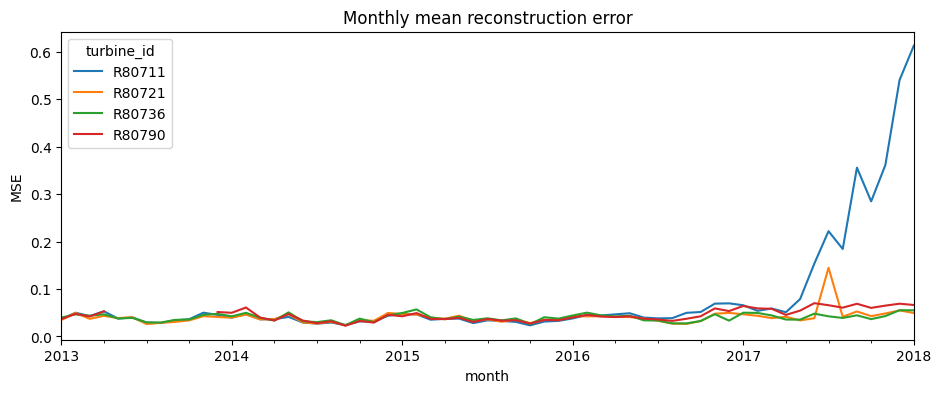

            val   test  x_times
gost_avg  0.052  0.809     15.6
git_avg   0.130  0.912      7.0
db1t_avg  0.038  0.190      5.0
gb2t_avg  0.046  0.214      4.7
yt_avg    0.040  0.173      4.3
dst_avg   0.038  0.160      4.2
gb1t_avg  0.063  0.241      3.8
rt_avg    0.006  0.018      3.2
rbt_avg   0.007  0.019      2.9
s_avg     0.049  0.115      2.4
p_avg     0.049  0.115      2.3
ws_avg    0.056  0.125      2.2
q_avg     0.056  0.118      2.1
db2t_avg  0.045  0.088      2.0
ds_avg    0.054  0.086      1.6
dcs_avg   0.054  0.087      1.6

gost_avg monthly level (scaled), R80711:
month
2016-02    0.44
2016-03    0.36
2016-04    0.38
2016-05    0.47
2016-06    0.48
2016-07    0.46
2016-08    0.62
2016-09    0.69
2016-10    0.55
2016-11    0.67
2016-12    0.39
2017-01    0.39
2017-02    0.59
2017-03    0.80
2017-04    0.48
2017-05    0.70
2017-06    1.37
2017-07    1.63
2017-08    1.40
2017-09    1.85
2017-10    1.73
2017-11    1.75
2017-12    1.92
2018-01    2.44
Freq: M, Name: lvl, dtyp

In [3]:
import matplotlib.pyplot as plt

meta["month"] = pd.to_datetime(meta["end_ts"]).dt.to_period("M")

# 1) Mahine-wise mean error, har turbine (kab badha?)
monthly = meta.groupby(["month", "turbine_id"])["err"].mean().unstack()
print(monthly.tail(24).round(3))
monthly.plot(figsize=(11, 4), title="Monthly mean reconstruction error")
plt.ylabel("MSE"); plt.show()

# 2) R80711: test mein kaunse sensors ka error val ke muqable zyada hai
is711 = (meta.turbine_id == "R80711").values
val711  = sensor_err[is711 & (meta.split == "val").values].mean(0)
test711 = sensor_err[is711 & (meta.split == "test").values].mean(0)
cmp = pd.DataFrame({"val": val711, "test": test711}, index=FEATURES)
cmp["x_times"] = (cmp.test / cmp.val).round(1)          # test mein val se kitna guna zyada
print(cmp.sort_values("x_times", ascending=False).round(3))

# 3) Sabse bigde hue sensor ka level mahine-wise (scaled units mein)
top = cmp["x_times"].idxmax()
j = FEATURES.index(top)
meta["lvl"] = X[:, :, j].mean(axis=1)                   # us sensor ka window average
lvl = meta[meta.turbine_id == "R80711"].groupby("month")["lvl"].mean()
print(f"\n{top} monthly level (scaled), R80711:"); print(lvl.tail(24).round(2))

In [4]:
import numpy as np, pandas as pd
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

# Classical models ko 3D window nahi chahiye: har window ko 32 numbers mein badlo (16 sensors ka mean + std)
F = np.concatenate([X.mean(axis=1), X.std(axis=1)], axis=1)       # (91852, 32)
tr = (meta.split == "train").values

scores = {"LSTM-AE": meta["err"].values}                          # LSTM ka score pehle se hai

# 1) Z-score: X pehle se train-scaled hai, to window mean hi z-score hai. Sabse bigda sensor lo
scores["Z-score"] = np.abs(X.mean(axis=1)).max(axis=1)

# 2) PCA: sirf train se structure seekho, reconstruction error = score
pca = PCA(n_components=0.95, random_state=0).fit(F[tr])           # 95% variance rakho
scores["PCA"] = ((F - pca.inverse_transform(pca.transform(F))) ** 2).mean(axis=1)

# 3) Isolation Forest: sirf train pe fit
iso = IsolationForest(n_estimators=200, random_state=0, n_jobs=-1).fit(F[tr])
scores["IsoForest"] = -iso.score_samples(F)                       # bada = zyada anomalous

# ---- Compare: sabke liye same threshold rule (val ka 99th percentile, har turbine ke liye alag) ----
end = pd.to_datetime(meta["end_ts"])
suspect = ((meta.turbine_id == "R80711") & (end >= "2017-06-01")).values        # PROXY label (neeche padho)
others_test = ((meta.split == "test") & (meta.turbine_id != "R80711")).values   # baaki 3 turbines ka test
is_val = (meta.split == "val")

rows = []
for name, s in scores.items():
    s = pd.Series(s, index=meta.index)
    thr = s[is_val].groupby(meta.turbine_id).quantile(0.99)
    flag = s > meta.turbine_id.map(thr)
    rows.append({"method": name,
                 "val_flag_%": 100 * flag[is_val].mean(),                      # ~1% hona chahiye
                 "R80711_suspect_flagged_%": 100 * flag[suspect].mean(),       # jitna zyada utna achha
                 "other3_test_flagged_%": 100 * flag[others_test].mean()})     # jitna kam utna achha
print(pd.DataFrame(rows).round(1).to_string(index=False))

   method  val_flag_%  R80711_suspect_flagged_%  other3_test_flagged_%
  LSTM-AE         1.0                      52.3                    2.3
  Z-score         1.0                      10.2                    0.7
      PCA         1.0                       2.5                    1.7
IsoForest         1.0                       1.8                    1.5


In [5]:
pd.DataFrame(scores).assign(turbine_id=meta.turbine_id.values, end_ts=meta.end_ts.values,
                            split=meta.split.values).to_parquet(f"{D}/scores_all_methods.parquet")
print("saved")

saved


In [7]:
# Colab restart hua ho to pehle: !pip -q install pyspark   (Java 21 pehle se hai)
import numpy as np, pandas as pd, torch, pyarrow as pa, pyarrow.parquet as pq
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.master("local[*]").appName("scada-score")
         .config("spark.sql.execution.arrow.maxRecordsPerBatch", "1024")   # ek batch mein 1024 windows
         .getOrCreate())

# Har window (36x16) ko 576 numbers ki flat list bana ke Parquet mein likho
flat = X.reshape(len(X), -1).astype("float32")                      # (91852, 576)
tbl = pa.table({
    "turbine_id": pa.array(meta.turbine_id.values),
    "end_ts": pa.array(pd.to_datetime(meta.end_ts).values.astype("datetime64[us]")),
    "w": pa.FixedSizeListArray.from_arrays(pa.array(flat.ravel()), 576),
})
pq.write_to_dataset(tbl, root_path="/content/windows_pq", partition_cols=["turbine_id"])   # 4 turbine = 4 partitions
print("written:", len(X), "windows")

written: 91852 windows


In [8]:
import time
from typing import Iterator
from pyspark.sql.functions import pandas_udf

# Weights ko numpy mein badal ke broadcast (har worker ko ek copy)
w_np = {k: v.detach().cpu().numpy() for k, v in model.state_dict().items()}
w_bc = spark.sparkContext.broadcast(w_np)

@pandas_udf("double")
def score_udf(batches: Iterator[pd.Series]) -> Iterator[pd.Series]:
    import torch
    torch.set_num_threads(1)                                  # har worker 1 thread, cores aapas mein na ladein
    m = LSTMAE()                                              # class notebook mein pehle se defined hai (Resume cell)
    m.load_state_dict({k: torch.tensor(v) for k, v in w_bc.value.items()})
    m.eval()                                                  # model ek baar load, har batch pe nahi
    for s in batches:
        xb = torch.tensor(np.stack(s.to_numpy()).reshape(-1, 36, 16), dtype=torch.float32)
        with torch.no_grad():
            err = ((m(xb) - xb) ** 2).mean(dim=(1, 2)).numpy()    # window ka reconstruction error
        yield pd.Series(err.astype("float64"))

scored = (spark.read.parquet("/content/windows_pq")
               .withColumn("err", score_udf("w"))
               .drop("w"))

t0 = time.time()
res = scored.toPandas()                                       # yahan asli computation hota hai
t_spark = time.time() - t0
print(f"Spark scoring: {len(res)} windows in {t_spark:.1f}s")

# Correctness check: Spark ke scores vs pehle wale single-process scores
ms = pd.read_parquet(f"{D}/meta_scored.parquet")[["turbine_id", "end_ts", "err"]]
for d in (res, ms):
    d["end_ts"] = pd.to_datetime(d["end_ts"]).astype("datetime64[ns]")
chk = res.merge(ms, on=["turbine_id", "end_ts"], suffixes=("_spark", "_single"))
print("matched rows:", len(chk))                              # 91,852 aana chahiye
print("max abs diff:", float(np.abs(chk.err_spark - chk.err_single).max()))

Spark scoring: 183704 windows in 34.9s
matched rows: 183704
max abs diff: 2.1770596504211426e-05


In [9]:
import shutil, time

# 1) Purana (doubled) data hatao aur ek baar fresh likho
shutil.rmtree("/content/windows_pq", ignore_errors=True)
pq.write_to_dataset(tbl, root_path="/content/windows_pq", partition_cols=["turbine_id"])
print("windows in parquet:", spark.read.parquet("/content/windows_pq").count())   # 91852 aana chahiye

# 2) scored DataFrame dobara banao (purana wala purani file listing yaad rakhta hai)
scored = (spark.read.parquet("/content/windows_pq")
               .withColumn("err", score_udf("w"))
               .drop("w"))

t0 = time.time()
res = scored.toPandas()
t_spark = time.time() - t0
print(f"Spark scoring: {len(res)} windows in {t_spark:.1f}s ({len(res)/t_spark:.0f} windows/s)")

# 3) Correctness: ab exactly 91,852 match hone chahiye
res["end_ts"] = pd.to_datetime(res["end_ts"]).astype("datetime64[ns]")
chk = res.merge(ms, on=["turbine_id", "end_ts"], suffixes=("_spark", "_single"))
print("matched rows:", len(chk), "| duplicates in res:", res.duplicated(["turbine_id", "end_ts"]).sum())
print("max abs diff:", float(np.abs(chk.err_spark - chk.err_single).max()))

# 4) Single-process GPU scoring ka time (reference ke liye)
t0 = time.time(); _ = recon_error(X); t_gpu = time.time() - t0
print(f"Single-process GPU: {len(X)} windows in {t_gpu:.1f}s")

windows in parquet: 91852
Spark scoring: 91852 windows in 25.0s (3679 windows/s)
matched rows: 91852 | duplicates in res: 0
max abs diff: 2.1770596504211426e-05
Single-process GPU: 91852 windows in 0.6s


In [10]:
# 1) Scores ko Spark se Parquet mein likho (pipeline ka natural end: score -> store)
scored.write.mode("overwrite").parquet("/content/scores_pq")           # ~25 s, UDF yahan chalta hai
scores = spark.read.parquet("/content/scores_pq")
scores.createOrReplaceTempView("scores")

# 2) LSTM thresholds (val ka 99th percentile, har turbine ke liye) ko chhoti table banao
thr_lstm = meta[meta.split == "val"].groupby("turbine_id")["err"].quantile(0.99)
spark.createDataFrame(thr_lstm.rename("thr").reset_index()).createOrReplaceTempView("thr")

# 3) Daily health score: plain SQL GROUP BY + JOIN
health = spark.sql("""
    SELECT s.turbine_id,
           CAST(s.end_ts AS DATE)                                              AS day,
           COUNT(*)                                                            AS n_windows,
           ROUND(AVG(s.err), 4)                                                AS mean_err,
           ROUND(AVG(CASE WHEN s.err > t.thr THEN 1.0 ELSE 0.0 END), 3)        AS flag_frac,
           ROUND(100 * (1 - AVG(CASE WHEN s.err > t.thr THEN 1.0 ELSE 0.0 END)), 1) AS health_score,
           COUNT(*) < 6                                                        AS low_coverage   -- din mein 6 se kam windows = bharosa kam
    FROM scores s JOIN thr t ON s.turbine_id = t.turbine_id
    GROUP BY s.turbine_id, CAST(s.end_ts AS DATE)
""")
health.createOrReplaceTempView("health")
print("turbine-days:", health.count())

# 4) R80711 ke aakhri 15 din
health.filter("turbine_id = 'R80711'").orderBy(F.desc("day")).show(15, truncate=False)

# 5) Mahine-wise average health, saari turbines, aakhri 12 mahine
monthly = spark.sql("""
    SELECT date_format(day, 'yyyy-MM') AS month, turbine_id, ROUND(AVG(health_score), 1) AS avg_health
    FROM health WHERE n_windows >= 6
    GROUP BY 1, 2
""").toPandas()
print(monthly.pivot(index="month", columns="turbine_id", values="avg_health").tail(12))

# 6) Drive mein save
health.toPandas().to_parquet(f"{D}/daily_health.parquet")
print("saved daily_health.parquet")

turbine-days: 6453
+----------+----------+---------+--------+---------+------------+------------+
|turbine_id|day       |n_windows|mean_err|flag_frac|health_score|low_coverage|
+----------+----------+---------+--------+---------+------------+------------+
|R80711    |2018-01-12|2        |0.0187  |0.000    |100.0       |true        |
|R80711    |2018-01-10|18       |0.0768  |0.000    |100.0       |false       |
|R80711    |2018-01-09|14       |0.3129  |0.714    |28.6        |false       |
|R80711    |2018-01-08|24       |0.839   |1.000    |0.0         |false       |
|R80711    |2018-01-07|24       |0.7397  |0.708    |29.2        |false       |
|R80711    |2018-01-06|10       |0.0668  |0.000    |100.0       |false       |
|R80711    |2018-01-05|13       |0.312   |0.923    |7.7         |false       |
|R80711    |2018-01-04|7        |1.1206  |1.000    |0.0         |false       |
|R80711    |2018-01-03|9        |1.2492  |1.000    |0.0         |false       |
|R80711    |2018-01-02|8        |

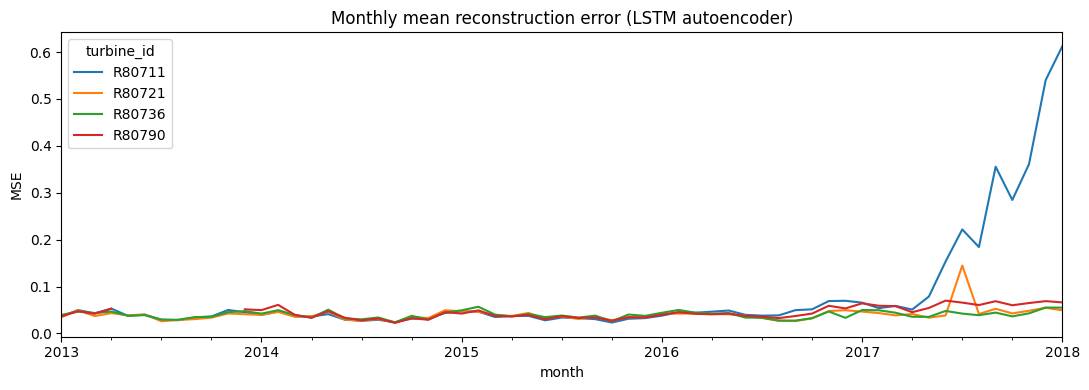

['monthly_error.png', 'baseline_comparison.csv', 'daily_health.csv']


In [11]:
import os, pandas as pd, matplotlib.pyplot as plt
os.makedirs(f"{D}/results", exist_ok=True)

# 1) Monthly reconstruction error chart (naam se `monthly` pehle overwrite ho chuka hai, isliye dobara banao)
meta["month"] = pd.to_datetime(meta["end_ts"]).dt.to_period("M")
err_m = meta.groupby(["month", "turbine_id"])["err"].mean().unstack()
ax = err_m.plot(figsize=(11, 4), title="Monthly mean reconstruction error (LSTM autoencoder)")
ax.set_ylabel("MSE"); plt.tight_layout()
plt.savefig(f"{D}/results/monthly_error.png", dpi=150); plt.show()

# 2) Baseline comparison table (tumhare printed numbers)
pd.DataFrame({
    "method": ["LSTM-AE", "Z-score", "PCA", "IsolationForest"],
    "val_flag_pct": [1.0, 1.0, 1.0, 1.0],
    "R80711_suspect_flagged_pct": [52.3, 10.2, 2.5, 1.8],
    "other3_test_flagged_pct": [2.3, 0.7, 1.7, 1.5],
}).to_csv(f"{D}/results/baseline_comparison.csv", index=False)

# 3) Daily health score (poora, ~6,453 rows)
pd.read_parquet(f"{D}/daily_health.parquet").to_csv(f"{D}/results/daily_health.csv", index=False)
print(os.listdir(f"{D}/results"))